# Wireless Communication Networks and Systems
## LAB 05: Propagation and Path Loss Models
*Python simulation*

---
### General Objectives
At the end of this session, students will be able to:
- Understand the concept of radio wave propagation and path loss.
- Differentiate between free-space path loss and empirical models.
- Use simple equations to simulate the effect of distance on received power.
- Visualize how signal strength decreases in different propagation environments.
- Relate path loss to real-world scenarios such as Wi-Fi or cellular coverage.

### Pedagogical Context
In wireless communication, signals weaken as they travel through space or obstacles. This session introduces students to the idea of attenuation using simple mathematical models:
1. **Free-space path loss (FSPL):** radio signal attenuation without obstacles.
2. **Log-distance model:** generalization accounting for environmental effects.
3. **Influence of frequency:** higher frequencies attenuate faster.

Instead of advanced physics, students will experiment with formulas and plots to understand how coverage areas are limited by distance, frequency, and environment.

### Tools Required
- Python 3.x
- Libraries: `numpy`, `matplotlib`
- Jupyter Notebook recommended

---
## Step 0 — Setup & Plotting Configuration
Initialize the workspace, configure plot styles, and ensure the output directory for figures exists.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Create figures directory if it doesn't exist
os.makedirs("figures", exist_ok=True)

# Plot styling configuration
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.6,
    "font.size": 11,
    "lines.linewidth": 2
})

---
## Step 1 — Free-Space Path Loss Formula

### Theoretical Background
Free-Space Path Loss (FSPL) models the attenuation of radio frequency signals traveling through unobstructed free space (Line-of-Sight, LOS) where spherical wavefront expansion is the sole attenuation mechanism.

From Friis' transmission equation for isotropic antennas ($G_t = G_r = 1$):
$$\frac{P_{rx}}{P_t} = \left(\frac{\lambda}{4\pi d}\right)^2 = \left(\frac{c}{4\pi d f}\right)^2$$

Expressed in decibels (dB), path loss $PL = 10\log_{10}(P_t / P_{rx})$ is:
$$PL_{FS}\text{ (dB)} = 20\log_{10}(d) + 20\log_{10}(f) + 32.44$$

where:
- $d$ is distance in **kilometers (km)**
- $f$ is frequency in **megahertz (MHz)**
- The constant $32.44\text{ dB}$ is derived from $20\log_{10}\left(\frac{4\pi \times 10^3 \times 10^6}{3 \times 10^8}\right) = 20\log_{10}\left(\frac{40\pi}{3}\right) \approx 32.44\text{ dB}$.

**Task:** Implement this formula in Python to compute and plot path loss for distances from $10\text{ m}$ ($0.01\text{ km}$) to $10\text{ km}$ at $f = 2400\text{ MHz}$ (2.4 GHz Wi-Fi).

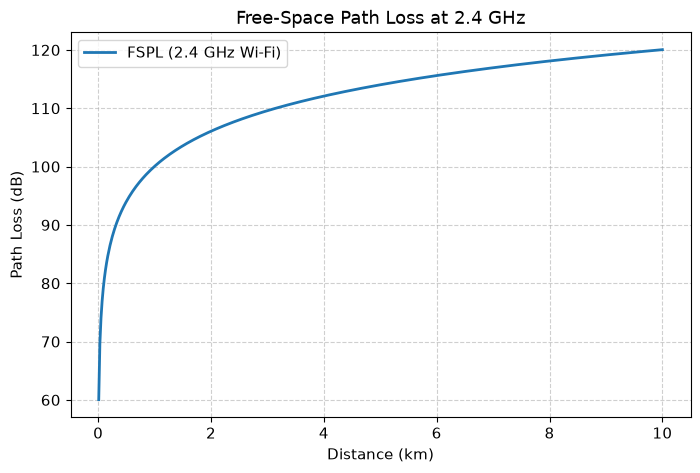

In [2]:
# Frequency: 2.4 GHz Wi-Fi
f = 2400  # MHz
d = np.linspace(0.01, 10, 500)  # distance from 10 m to 10 km

PL_fs = 20 * np.log10(d) + 20 * np.log10(f) + 32.44

plt.figure(figsize=(8, 5))
plt.plot(d, PL_fs, color="tab:blue", label="FSPL (2.4 GHz Wi-Fi)")
plt.xlabel("Distance (km)")
plt.ylabel("Path Loss (dB)")
plt.title("Free-Space Path Loss at 2.4 GHz")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.savefig("figures/step1_fspl_2400mhz.png", dpi=150, bbox_inches="tight")
plt.show()

### 1B. Path Loss on Logarithmic Distance Scale
When plotted against distance on a logarithmic scale ($\log_{10} d$), the FSPL relationship becomes a straight line with a characteristic slope of $20\text{ dB/decade}$ (every tenfold increase in distance adds exactly $20\text{ dB}$ of attenuation).

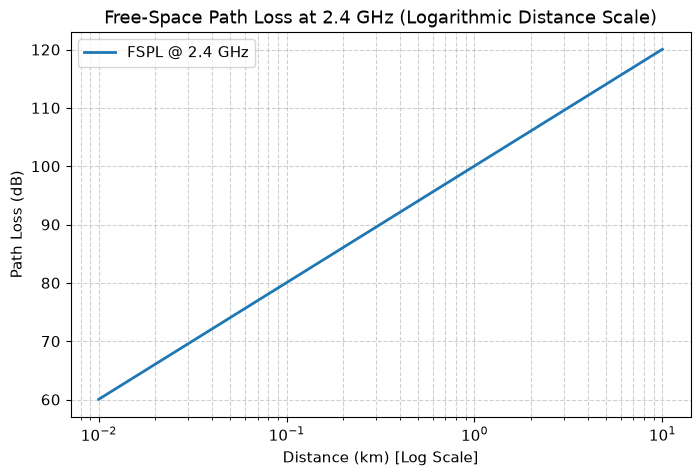

In [3]:
plt.figure(figsize=(8, 5))
plt.semilogx(d, PL_fs, color="tab:blue", label="FSPL @ 2.4 GHz")
plt.xlabel("Distance (km) [Log Scale]")
plt.ylabel("Path Loss (dB)")
plt.title("Free-Space Path Loss at 2.4 GHz (Logarithmic Distance Scale)")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.savefig("figures/step1_fspl_logscale.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Step 2 — Effect of Frequency

### Theoretical Background
As carrier frequency $f$ increases, the wavelength $\lambda = c / f$ decreases proportionally. Because the effective aperture of an isotropic antenna is:
$$A_e = \frac{\lambda^2}{4\pi} = \frac{c^2}{4\pi f^2}$$
higher frequency antennas intercept a smaller physical area of the expanding spherical wavefront. As a result, higher frequencies experience greater path loss over identical distances.

**Task:** Compare FSPL across three key wireless frequency bands:
1. **$900\text{ MHz}$:** Cellular (GSM / LTE low-band / IoT)
2. **$2400\text{ MHz}$ ($2.4\text{ GHz}$):** Standard Wi-Fi 4 / Bluetooth
3. **$5800\text{ MHz}$ ($5.8\text{ GHz}$):** High-speed Wi-Fi 5 / Wi-Fi 6

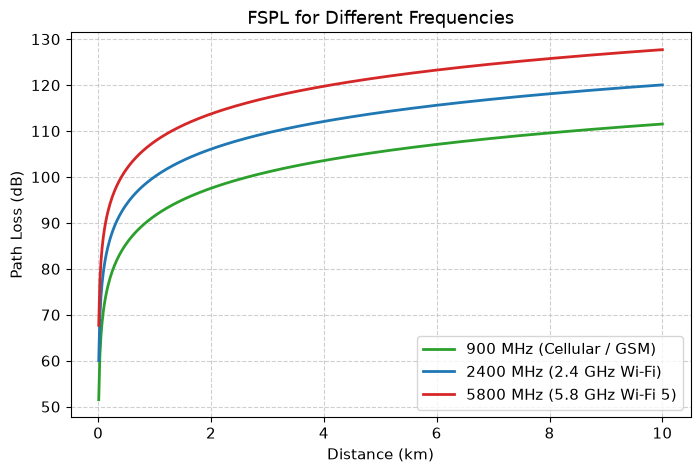

In [4]:
frequencies = [900, 2400, 5800]
band_names = {
    900: "900 MHz (Cellular / GSM)",
    2400: "2400 MHz (2.4 GHz Wi-Fi)",
    5800: "5800 MHz (5.8 GHz Wi-Fi 5)"
}
colors = {900: "tab:green", 2400: "tab:blue", 5800: "tab:red"}

plt.figure(figsize=(8, 5))
for f_val in frequencies:
    PL = 20 * np.log10(d) + 20 * np.log10(f_val) + 32.44
    plt.plot(d, PL, label=band_names[f_val], color=colors[f_val])

plt.xlabel("Distance (km)")
plt.ylabel("Path Loss (dB)")
plt.title("FSPL for Different Frequencies")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.savefig("figures/step2_frequency_effect.png", dpi=150, bbox_inches="tight")
plt.show()

### 2B. Quantitative Frequency Offset Analysis
Notice that the curves are parallel on the dB scale. The path loss difference between any two frequencies $f_1$ and $f_2$ is independent of distance: $\Delta PL = 20\log_{10}(f_2 / f_1)$.

In [5]:
d_ref = 1.0  # km
print(f"Path Loss at d = {d_ref} km:")
for f_val in frequencies:
    pl_val = 20 * np.log10(d_ref) + 20 * np.log10(f_val) + 32.44
    print(f"  • {band_names[f_val]:30s}: {pl_val:.2f} dB")

print("\nAdditional Path Loss relative to 900 MHz:")
for f_val in [2400, 5800]:
    penalty = 20 * np.log10(f_val / 900)
    print(f"  • {f_val} MHz vs 900 MHz: +{penalty:.2f} dB additional attenuation")

Path Loss at d = 1.0 km:
  • 900 MHz (Cellular / GSM)      : 91.52 dB
  • 2400 MHz (2.4 GHz Wi-Fi)      : 100.04 dB
  • 5800 MHz (5.8 GHz Wi-Fi 5)    : 107.71 dB

Additional Path Loss relative to 900 MHz:
  • 2400 MHz vs 900 MHz: +8.52 dB additional attenuation
  • 5800 MHz vs 900 MHz: +16.18 dB additional attenuation

---
## Step 3 — Log-Distance Path Loss Model

### Theoretical Background
In practical wireless propagation environments, signals reflect from the ground, scatter off walls, diffract around buildings, and penetrate obstacles. Under these conditions, signal attenuation does not follow the free-space square-law.

The **Log-Distance Path Loss Model** captures these real-world propagation characteristics via an empirical **path loss exponent** $n$:
$$PL(d) = PL(d_0) + 10n \log_{10}\left(\frac{d}{d_0}\right)$$

where:
- $d_0$ is a close-in reference distance ($d_0 = 0.1\text{ km} = 100\text{ m}$ for outdoor environments).
- $PL(d_0)$ is the reference path loss at $d_0$, typically computed using the free-space model:
  $$PL(d_0) = 20\log_{10}(0.1) + 20\log_{10}(2400) + 32.44 = 80.04\text{ dB}$$
- $n$ is the path loss exponent:
  - $n = 2$: Free space (ideal line-of-sight)
  - $n \approx 3$: Urban cellular radio environment
  - $n \approx 4 - 5$: Indoor, obstructed, or heavily shadowed environment

**Task:** Simulate and plot the log-distance model for $n \in [2, 3, 4, 5]$ over distances from $d_0 = 100\text{ m}$ to $10\text{ km}$ at $f = 2400\text{ MHz}$.

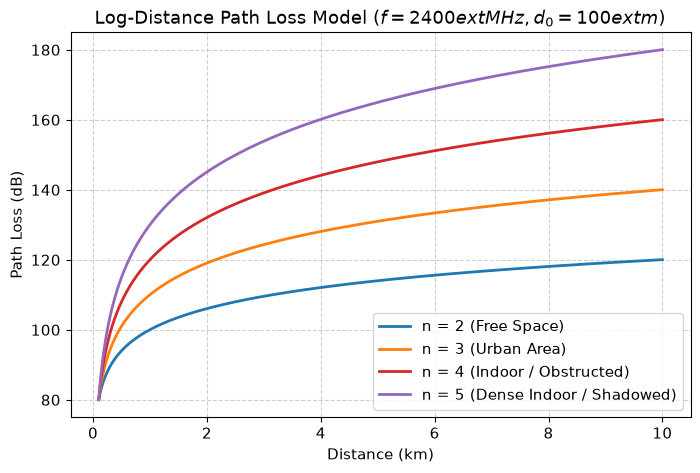

In [6]:
d0 = 0.1  # reference distance = 100 m = 0.1 km
f = 2400  # MHz
PL_d0 = 20 * np.log10(d0) + 20 * np.log10(f) + 32.44

# Distances from d0 (100 m) up to 10 km
d_range = np.linspace(d0, 10, 500)

environments = [
    (2, "n = 2 (Free Space)", "tab:blue"),
    (3, "n = 3 (Urban Area)", "tab:orange"),
    (4, "n = 4 (Indoor / Obstructed)", "tab:red"),
    (5, "n = 5 (Dense Indoor / Shadowed)", "tab:purple")
]

plt.figure(figsize=(8, 5))
for n_val, label, col in environments:
    PL = PL_d0 + 10 * n_val * np.log10(d_range / d0)
    plt.plot(d_range, PL, label=label, color=col)

plt.xlabel("Distance (km)")
plt.ylabel("Path Loss (dB)")
plt.title("Log-Distance Path Loss Model ($f = 2400\text{ MHz}, d_0 = 100\text{ m}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.savefig("figures/step3_log_distance_model.png", dpi=150, bbox_inches="tight")
plt.show()

### 3B. Log-Distance Model on Logarithmic Distance Scale
On a logarithmic distance axis, each curve becomes a straight line with slope equal to $10n\text{ dB/decade}$. This clearly illustrates how higher exponents cause path loss to escalate much more steeply.

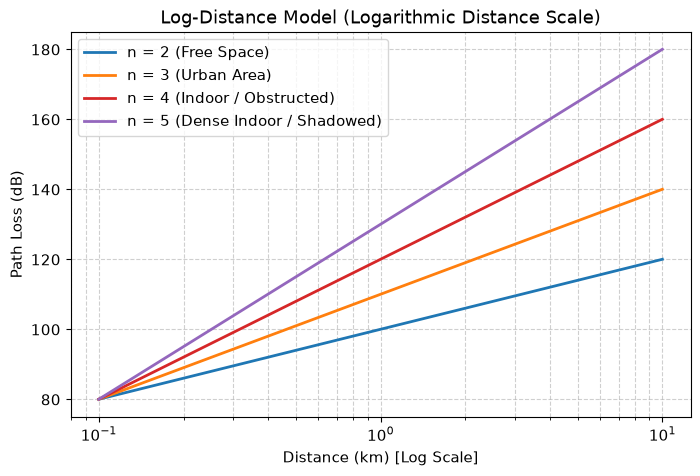

In [7]:
plt.figure(figsize=(8, 5))
for n_val, label, col in environments:
    PL = PL_d0 + 10 * n_val * np.log10(d_range / d0)
    plt.semilogx(d_range, PL, label=label, color=col)

plt.xlabel("Distance (km) [Log Scale]")
plt.ylabel("Path Loss (dB)")
plt.title("Log-Distance Model (Logarithmic Distance Scale)")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.savefig("figures/step3_log_distance_semilogx.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Step 4 — Coverage Estimation

### Theoretical Formulation & Link Budget
In link budget design, reliable communication requires the received power $P_{rx}(d)$ to meet or exceed the receiver sensitivity threshold $P_{rx,min}$:
$$P_{rx}(d) \ge P_{rx,min}$$

Expressed in dBm:
$$P_{rx}(d)\text{ (dBm)} = P_t\text{ (dBm)} - PL(d)$$

Thus, the maximum permissible path loss $PL_{max}$ is:
$$PL(d) \le P_t - P_{rx,min} \implies PL_{max} = P_t - P_{rx,min}$$

**Given Parameters:**
- Transmit power: $P_t = +20\text{ dBm}$ ($100\text{ mW}$)
- Receiver sensitivity: $P_{rx,min} = -90\text{ dBm}$ ($1\text{ pW}$)
- Carrier frequency: $f = 2400\text{ MHz}$
- Reference distance: $d_0 = 0.1\text{ km} = 100\text{ m}$

$$PL_{max} = 20\text{ dBm} - (-90\text{ dBm}) = 110\text{ dB}$$

#### Analytical Calculation:
1. **Free-Space Model ($n = 2$):**
   $$PL_{FS}(d) = 20\log_{10}(d) + 20\log_{10}(2400) + 32.44 = 110$$
   $$20\log_{10}(d) + 100.04 = 110 \implies 20\log_{10}(d) = 9.96$$
   $$d_{max, FS} = 10^{\frac{9.96}{20}} \approx 3.148\text{ km} \quad (3148\text{ m})$$

2. **Urban Area Model ($n = 3$, $d_0 = 0.1\text{ km}$):**
   $$PL(d_0) + 10(3)\log_{10}\left(\frac{d}{d_0}\right) = 110 \implies 80.04 + 30\log_{10}\left(\frac{d}{0.1}\right) = 110$$
   $$30\log_{10}\left(\frac{d}{0.1}\right) = 29.96 \implies d_{max, urban} = 0.1 \times 10^{\frac{29.96}{30}} \approx 0.997\text{ km} \quad (997\text{ m})$$

3. **Indoor / Obstructed Model ($n = 4$, $d_0 = 0.1\text{ km}$):**
   $$40\log_{10}\left(\frac{d}{0.1}\right) = 29.96 \implies d_{max, indoor} = 0.1 \times 10^{\frac{29.96}{40}} \approx 0.561\text{ km} \quad (561\text{ m})$$

**Task:** Compute the maximum coverage distance for free-space and urban models, and visualize received power vs. distance with respect to the sensitivity threshold.

In [8]:
Pt = 20.0        # dBm (Transmit power)
Prx_min = -90.0  # dBm (Receiver sensitivity)
PL_max = Pt - Prx_min  # 110 dB

print(f"=== Coverage Budget Calculations ===")
print(f"Transmit Power (Pt):             {Pt:+.1f} dBm")
print(f"Receiver Sensitivity (Prx_min):  {Prx_min:+.1f} dBm")
print(f"Maximum Allowed Path Loss:        {PL_max:.1f} dB\n")

# Free-space analytical distance
d_max_fs = 10 ** ((PL_max - 20 * np.log10(f) - 32.44) / 20)

coverage_data = [
    ("Free-Space (n=2)", 2, d_max_fs),
]

for n_val, label, _ in environments[1:]:
    d_max_n = d0 * (10 ** ((PL_max - PL_d0) / (10 * n_val)))
    coverage_data.append((label, n_val, d_max_n))

print(f"{'Propagation Model':<32} {'Exponent n':<12} {'Max Distance (km)':<20} {'Max Distance (m)':<15}")
print("-" * 80)
for label, n_val, d_max_val in coverage_data:
    print(f"{label:<32} {n_val:<12} {d_max_val:<20.3f} {d_max_val * 1000:<15.1f}")

=== Coverage Budget Calculations ===
Transmit Power (Pt):             +20.0 dBm
Receiver Sensitivity (Prx_min):  -90.0 dBm
Maximum Allowed Path Loss:        110.0 dB

Propagation Model                Exponent n   Max Distance (km)    Max Distance (m)
--------------------------------------------------------------------------------
Free-Space (n=2)                 2            3.146                3146.2         
n = 3 (Urban Area)               3            0.997                996.6          
n = 4 (Indoor / Obstructed)      4            0.561                560.9          
n = 5 (Dense Indoor / Shadowed)  5            0.397                397.3

### 4B. Visualizing Coverage Limits & Received Power Curves
The dual plot below illustrates:
1. **Path Loss vs. Distance:** Highlighting the maximum allowable loss $PL_{max} = 110	ext{ dB}$.
2. **Received Power vs. Distance:** Showing where each environment crosses the sensitivity threshold $P_{rx,min} = -90	ext{ dBm}$.

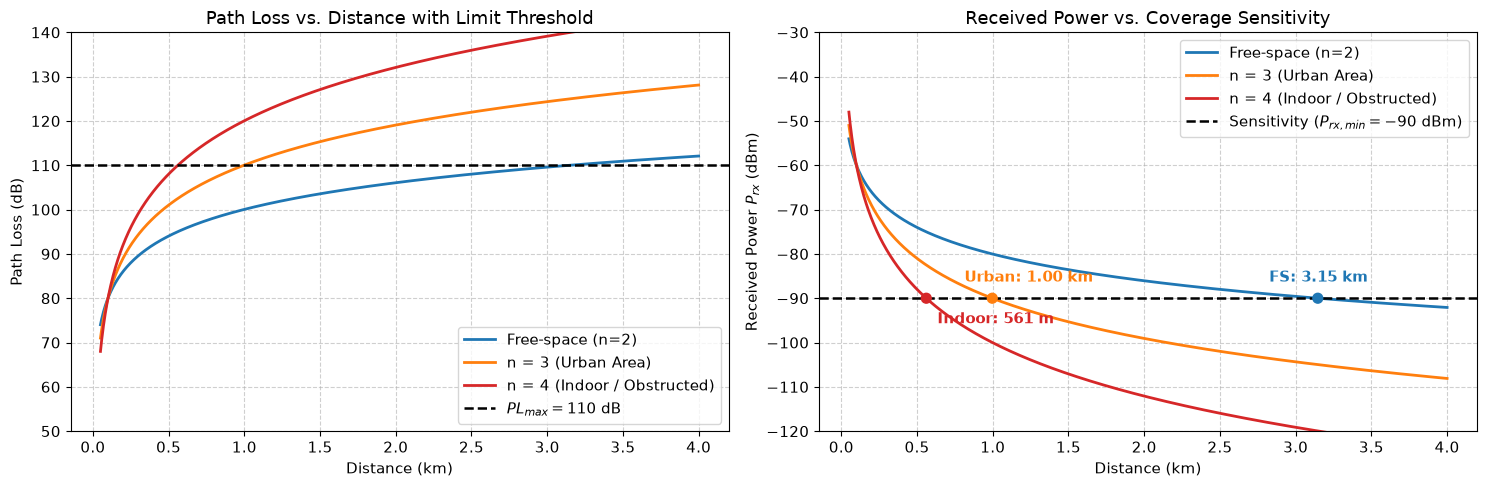

In [9]:
d_sim = np.linspace(0.05, 4.0, 1000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# --- Plot 1: Path Loss vs Distance ---
PL_fs_sim = 20 * np.log10(d_sim) + 20 * np.log10(f) + 32.44
ax1.plot(d_sim, PL_fs_sim, label="Free-space (n=2)", color="tab:blue")

for n_val, label, col in environments[1:3]:
    pl_sim = PL_d0 + 10 * n_val * np.log10(d_sim / d0)
    ax1.plot(d_sim, pl_sim, label=label, color=col)

ax1.axhline(PL_max, color="black", linestyle="--", lw=1.8, label=f"$PL_{{max}} = {PL_max:.0f}$ dB")
ax1.set_xlabel("Distance (km)")
ax1.set_ylabel("Path Loss (dB)")
ax1.set_title("Path Loss vs. Distance with Limit Threshold")
ax1.set_ylim(50, 140)
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.6)

# --- Plot 2: Received Power Prx vs Distance ---
Prx_fs_sim = Pt - PL_fs_sim
ax2.plot(d_sim, Prx_fs_sim, label="Free-space (n=2)", color="tab:blue")

for n_val, label, col in environments[1:3]:
    prx_sim = Pt - (PL_d0 + 10 * n_val * np.log10(d_sim / d0))
    ax2.plot(d_sim, prx_sim, label=label, color=col)

ax2.axhline(Prx_min, color="black", linestyle="--", lw=1.8, label=f"Sensitivity ($P_{{rx,min}} = {Prx_min:.0f}$ dBm)")

# Mark intersection points
d_urban = d0 * (10 ** ((PL_max - PL_d0) / (10 * 3)))
d_indoor = d0 * (10 ** ((PL_max - PL_d0) / (10 * 4)))

ax2.scatter([d_max_fs, d_urban, d_indoor], [Prx_min, Prx_min, Prx_min], color=["tab:blue", "tab:orange", "tab:red"], s=50, zorder=5)
ax2.annotate(f"FS: {d_max_fs:.2f} km", (d_max_fs, Prx_min), textcoords="offset points", xytext=(-35, 12), weight="bold", color="tab:blue")
ax2.annotate(f"Urban: {d_urban:.2f} km", (d_urban, Prx_min), textcoords="offset points", xytext=(-20, 12), weight="bold", color="tab:orange")
ax2.annotate(f"Indoor: {d_indoor*1000:.0f} m", (d_indoor, Prx_min), textcoords="offset points", xytext=(8, -18), weight="bold", color="tab:red")

ax2.set_xlabel("Distance (km)")
ax2.set_ylabel("Received Power $P_{rx}$ (dBm)")
ax2.set_title("Received Power vs. Coverage Sensitivity")
ax2.set_ylim(-120, -30)
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("figures/step4_coverage_estimation.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Discussion Questions

### Question 1
Why does higher frequency lead to greater path loss?

**Answer:**
As carrier frequency $f$ increases, the signal's wavelength $\lambda = c / f$ gets shorter. Because an isotropic receiving antenna's effective capture area is proportional to $\lambda^2$ ($A_e = \frac{\lambda^2}{4\pi}$), a higher-frequency antenna physically intercepts a smaller portion of the expanding spherical wavefront.
- Mathematically, $PL_{FS}$ includes the $+20\log_{10}(f)$ term, meaning **doubling the frequency adds $+6.02\text{ dB}$ of path loss** at the same distance.
- In our simulation at $d = 1\text{ km}$, moving from $900\text{ MHz}$ ($91.52\text{ dB}$) to $2400\text{ MHz}$ ($100.04\text{ dB}$) adds $+8.52\text{ dB}$ of loss, and moving to $5800\text{ MHz}$ ($107.71\text{ dB}$) adds $+16.18\text{ dB}$.

### Question 2
What environmental factors can increase the path loss exponent n?

**Answer:**
In ideal free space ($n = 2$), signals only spread out spherically. In real-world environments, $n$ increases (typically to $3$–$5+$) due to obstacles and multipath effects:
- **Physical obstructions:** Concrete/brick walls, floors, furniture, metal structures, and buildings that absorb or block the signal.
- **Foliage & terrain:** Trees, leaves (especially when wet), hills, and uneven ground.
- **Multipath & scattering:** Reflections off buildings, vehicles, or indoor surfaces causing destructive interference, along with diffraction around sharp corners.
- **Clutter & atmospheric density:** Crowded indoor spaces, dense urban canyons, and rain/humidity at higher frequencies.

### Question 3
Why do indoor Wi-Fi networks have smaller coverage areas than outdoor cellular networks?

**Answer:**
Indoor Wi-Fi has a much smaller coverage area than outdoor cellular networks for three main reasons:
1. **Higher path loss exponent ($n$):** Indoors, walls, ceilings, and furniture push $n$ to $4$–$5$, whereas outdoor cellular links typically see $n \approx 3$ (or $n = 2$ in open areas). At $P_t = +20\text{ dBm}$ and $P_{rx,min} = -90\text{ dBm}$, our simulation showed coverage dropping from **$996.6\text{ m}$** (urban, $n=3$) down to **$560.9\text{ m}$** ($n=4$) and **$397.3\text{ m}$** ($n=5$).
2. **Higher carrier frequencies:** Wi-Fi operates at $2.4\text{ GHz}$ and $5.8\text{ GHz}$, which suffer greater free-space loss and penetrate walls poorly compared to lower cellular bands ($700$–$900\text{ MHz}$).
3. **Lower transmit power & antenna height:** Wi-Fi routers are legally capped at low power (around $+20\text{ dBm}$ / $100\text{ mW}$) and placed indoors at desk/ceiling height, while cellular base stations transmit at much higher power ($+40$ to $+46\text{ dBm}$) from tall towers with clearer line-of-sight.

### Question 4
How do transmit power and receiver sensitivity influence coverage distance?

**Answer:**
Together, transmit power ($P_t$) and receiver sensitivity ($P_{rx,min}$) set the **maximum allowed path loss**:
$$PL_{max} = P_t - P_{rx,min}$$
- **Increasing $P_t$** (stronger transmitter) or **lowering $P_{rx,min}$** (more sensitive receiver, e.g., $-90\text{ dBm} \to -100\text{ dBm}$) increases $PL_{max}$, allowing the signal to travel farther before dropping below the usable threshold.
- **Logarithmic scaling:** Because path loss grows logarithmically as $10n\log_{10}(d/d_0)$, every **$+10n\text{ dB}$** gain in the link budget multiplies the maximum coverage distance by **$10\times$** (or doubles the distance for every $+6\text{ dB}$ in free space where $n=2$, and every $+12\text{ dB}$ indoors where $n=4$).